# LEBIS — การเรียงลำดับและการจัดกลุ่ม (Sort & Group)

**วิชา Data Structures & Algorithms · ส่วนของ Kul**

LEBIS คือระบบยืม-คืนของร้านเช่าอุปกรณ์ถ่ายภาพ ร้านมีคำถามที่ต้องดูของ "ทั้งก้อน"
เช่น *"ใบไหนค้างนานที่สุด"* · *"ของชิ้นไหนใกล้หมด"* · *"ร้านมีกล้องอะไรบ้าง"* · *"ตอนนี้อะไรชำรุดอยู่"*

ฟิลด์ที่มีลำดับ (`due_date` · `available`) ใช้ **เรียง** ส่วนฟิลด์ที่เป็นป้ายชื่อ (`category` · `status`) ใช้ **จัดกลุ่ม**

| อัลกอริทึมกลุ่ม | ฟังก์ชัน | Big-O เวลา |
|---|---|---|
| Sorting (เขียนเอง) | `merge_sort` · `sort_by_due_date` · `sort_by_available` | O(n log n) |
| Sorting (ตัวเทียบ) | `bubble_sort` | O(n²) |
| Grouping | `group_by_type` · `group_by_status` | O(n) |

`sorted()` ของ Python ใช้เป็นตัวเทียบเวลาอย่างเดียว ไม่ได้ใช้ทำงานจริง

> ตัวเลขในรายงานฉบับรวมมาจาก `LEBIS_Final.ipynb` ไม่ใช่ notebook นี้
> notebook นี้รันคนละรอบ เวลาจึงขยับได้เล็กน้อย อย่าเอาไปผสมกับตัวเลขในรายงาน

**วิธีรัน:** เมนู Runtime → Run all

---
## 1. ชุดข้อมูลทดสอบ A–D

ใช้ `datasets.py` ชุดเดียวกับทั้งทีม ตัวเลขของสามหัวข้อจะได้เทียบกันได้

| ชุด | จำนวน | ลักษณะ | ใช้พิสูจน์อะไร |
|---|---|---|---|
| A | 10 | ข้อมูลสะอาด | ทุกฟังก์ชันทำงานถูก |
| B | 12 | ชื่อซ้ำ แต่รหัสไม่ซ้ำ | ชื่อซ้ำไม่มีผล เพราะไม่ได้ใช้ชื่อเป็นคีย์ |
| C | 10 | ของหมด 5 จาก 10 รายการ | `available = 0` ซ้ำกันหลายตัว — กรณีค่าเท่ากัน |
| D | 1,000 | ชุดใหญ่ | O(n²) กับ O(n log n) ต่างกันแค่ไหนเมื่อข้อมูลโต |

ชุด D เคยมี 120 รายการ แล้วทีมขยายเป็น 1,000 เพราะที่ 120 รายการความต่างยังไม่ชัดพอจะสรุป (ดู `plan.md`)
ขนาด 120 ยังอยู่เป็นจุดหนึ่งในกราฟของข้อ 4

> เซลล์ที่ขึ้นต้นด้วย `%%writefile` คือไฟล์จริงจากรีโปทุกตัวอักษร
> เขียนลงเป็นไฟล์แล้วค่อย `import` เพื่อให้แต่ละไฟล์มีชื่อตัวแปรเป็นของตัวเอง

In [1]:
%%writefile datasets.py
"""ชุดข้อมูลทดสอบ A–D — งานส่งวิชา Data Structures & Algorithms ของ Neo

ทั้งสามหัวข้อของกลุ่ม (hash_table ของ Kim · search ของ Neo · sort_group ของ Kul)
ต้องวัดผลบนข้อมูลชุดเดียวกันจากไฟล์นี้ ไม่ใช่ต่างคนต่างสร้างข้อมูลของตัวเอง
ถ้าแต่ละคนวัดบนข้อมูลคนละชุด ตัวเลขในรายงานจะอ่านเทียบกันไม่ได้เลย
และกรรมการจะเห็นทันทีว่าสามหัวข้อไม่ได้คุยกัน

🔴 กฎเหล็กของไฟล์นี้: import ได้แค่ standard library ของ Python เท่านั้น
   ห้าม FastAPI ห้าม databases ห้าม Pydantic ห้าม import ไฟล์อื่นในโปรเจกต์
   เพราะไฟล์เดียวกันนี้ถูกก็อปไปวางใน Google Colab แล้วต้องกดรันได้ทันที

วิธีรัน
    python3 backend-api/algorithms/datasets.py

วิธีใช้ใน Colab
    วางเซลล์ของไฟล์นี้ไว้ "ก่อน" เซลล์ของ hash_table.py และ search.py
    แล้วเรียก make_dataset("A") ... make_dataset("D") ส่งเข้าฟังก์ชันของแต่ละคน
    ได้ตรงๆ เพราะทุกตัวรับ list ของ dict ธรรมดา

หนึ่ง record มี 8 ฟิลด์ตามที่ Kim ออกแบบไว้
    code       รหัสอุปกรณ์ ไม่ซ้ำกันทั้งชุด — ใช้เป็น key ของตารางแฮช
    name       ชื่อที่คนเรียก ซ้ำกันได้ (ชุด B จงใจให้ซ้ำ)
    category   หมวด ใช้ตอนจัดกลุ่มของ Kul
    total      จำนวนทั้งหมดที่ร้านมี
    available  จำนวนที่ยังอยู่บนชั้นตอนนี้
    borrower   ชื่อผู้เช่า ถ้ายังไม่มีใครยืมเป็น None
    due_date   กำหนดคืนในรูป "YYYY-MM-DD" ถ้าไม่มีคนยืมเป็น None
    status     "ok" ว่างให้เช่าได้ · "out" ถูกยืมหมด · "broken" ชำรุด

ทำไมวันที่ถึงตายตัว
    count_overdue() ของ search.py นับจากวันครบกำหนดเทียบกับ "วันนี้"
    ถ้าใช้วันจริงของเครื่อง ตัวเลขในรายงานจะเปลี่ยนทุกวันที่รันใหม่
    และตัวเลขในรายงานกับตัวเลขในวิดีโอจะไม่ตรงกัน ไฟล์นี้จึงตรึง TODAY ไว้
    ให้ทุกคนอ้างอิงค่าเดียวกัน
"""

import random
from datetime import date, timedelta

# ---------------------------------------------------------------------------
# ส่วนที่ 1 — ค่าคงที่
# ---------------------------------------------------------------------------

# วันอ้างอิงตายตัว ใช้แทน "วันนี้" ทั้งระบบทดสอบ
# ตัวเลขในรายงานจึงเท่าเดิมทุกครั้งที่รัน ไม่ว่าจะรันวันไหน
TODAY = date(2026, 10, 1)

# หมวดและคำนำหน้ารหัส ใช้ชุดเดียวกับ hash_table.py ของ Kim
# (คัดลอกค่ามา ไม่ได้ import เพราะกฎ stdlib เท่านั้นข้างบน)
CATEGORIES = ["กล้อง", "เลนส์", "ขาตั้ง", "ไฟ", "ไมโครโฟน"]

CATEGORY_PREFIX = {
    "กล้อง": "CAM",
    "เลนส์": "LEN",
    "ขาตั้ง": "TRI",
    "ไฟ": "LED",
    "ไมโครโฟน": "MIC",
}

# ชื่อผู้เช่าสำหรับข้อมูลจำลอง ไม่ใช่ชื่อคนจริง
BORROWERS = [
    "ปวีณา",
    "ธนกร",
    "สุชาดา",
    "ณัฐพล",
    "กมลชนก",
    "อานนท์",
    "พิมพ์ชนก",
    "วีรภัทร",
]

# seed แยกตามชุด ชุดเดิมจึงได้ข้อมูลเดิมเสมอ แต่คนละชุดไม่เหมือนกัน
SEEDS = {"A": 11, "B": 22, "C": 33, "D": 44}

DATASET_SIZES = {"A": 10, "B": 12, "C": 10, "D": 1000}


# ---------------------------------------------------------------------------
# ส่วนที่ 2 — ตัวช่วยสร้าง record
# ---------------------------------------------------------------------------


def _iso(day: date) -> str:
    """แปลงวันเป็นข้อความ "YYYY-MM-DD"

    เก็บเป็นข้อความไม่ใช่ออบเจ็กต์ date เพราะรูปแบบนี้เรียงลำดับด้วยการเทียบ
    ข้อความได้ตรงๆ อยู่แล้ว (ปี-เดือน-วัน เรียงจากหน่วยใหญ่ไปเล็ก)
    merge_sort ของ Kul กับ binary_search ของ Neo จึงเทียบวันได้โดยไม่ต้องแปลงก่อน
    """
    return day.isoformat()


def _make_record(
    number: int,
    category: str,
    name: str,
    total: int,
    available: int,
    borrower=None,
    due_offset=None,
    broken: bool = False,
) -> dict:
    """ประกอบ record 8 ฟิลด์ให้ครบ และคิดค่า status ให้สอดคล้องกับ available

    due_offset คือจำนวนวันนับจาก TODAY ติดลบ = เลยกำหนดคืนมาแล้ว
    """
    if broken:
        status = "broken"
    elif available == 0:
        status = "out"
    else:
        status = "ok"

    return {
        "code": f"{CATEGORY_PREFIX[category]}-{number:04d}",
        "name": name,
        "category": category,
        "total": total,
        "available": available,
        "borrower": borrower,
        "due_date": _iso(TODAY + timedelta(days=due_offset)) if due_offset is not None else None,
        "status": status,
    }


def _build(size: int, seed: int, duplicate_names: bool, zero_stock: bool) -> list:
    """สร้างรายการตามพารามิเตอร์ที่แต่ละชุดต้องการ

    duplicate_names  ให้ชื่อซ้ำกันเป็นคู่ๆ แต่ code ยังไม่ซ้ำ (ชุด B)
    zero_stock       ดันให้หลายตัวมี available = 0 (ชุด C)
    """
    generator = random.Random(seed)
    items = []

    for number in range(1, size + 1):
        # ชุด B: ตัวเลขคู่ใช้ชื่อเดียวกับตัวก่อนหน้า จึงได้ชื่อซ้ำเป็นคู่ๆ
        # แต่ code ยังไม่ซ้ำ เพราะ code เดินตาม number ตลอด
        # ใช้พิสูจน์ว่าค้นด้วยชื่อแล้วยังแยกออกว่าเป็นตัวไหน
        #
        # หมวดต้องเดินตามชื่อไปด้วย ไม่งั้นจะได้ของที่ชื่อว่า "เลนส์ รุ่นที่ 1"
        # แต่หมวดเป็น "ขาตั้ง" ซึ่งเป็นข้อมูลที่ขัดกันเองและทำให้ group_by_type
        # ของ Kul ให้ผลที่อธิบายในรายงานไม่ได้
        name_number = number - 1 if duplicate_names and number % 2 == 0 else number
        category = CATEGORIES[name_number % len(CATEGORIES)]
        name = f"{category} รุ่นที่ {name_number}"

        total = generator.randint(1, 5)

        if zero_stock and number % 2 == 1:
            # ชุด C: ครึ่งหนึ่งถูกยืมไปหมด
            available = 0
        else:
            available = generator.randint(0, total)

        borrowed_units = total - available

        if borrowed_units > 0:
            borrower = BORROWERS[number % len(BORROWERS)]
            # กระจายกำหนดคืนไว้ทั้งก่อนและหลังวันอ้างอิง
            # ค่าติดลบคือเลยกำหนดแล้ว ซึ่งเป็นตัวที่ count_overdue() ต้องนับได้
            due_offset = generator.randint(-10, 14)
        else:
            borrower = None
            due_offset = None

        # ให้มีของชำรุดปนอยู่บ้าง เพื่อให้ count_by_status() มีครบทั้งสามสถานะ
        # ทุกๆ 7 ชิ้น — เลือกเลขนี้เพราะชุดเล็กสุดมี 10 ชิ้น ใช้ 7 แล้วยังได้
        # อย่างน้อย 1 ชิ้นในทุกชุด ถ้าใช้เลขที่ใหญ่กว่านั้น ชุด A-C จะไม่มีของชำรุดเลย
        # แล้วการนับสถานะ "broken" จะไม่เคยถูกทดสอบบนชุดที่ตรวจด้วยตาได้
        broken = number % 7 == 0

        items.append(
            _make_record(
                number=number,
                category=category,
                name=name,
                total=total,
                available=available,
                borrower=borrower,
                due_offset=due_offset,
                broken=broken,
            )
        )

    return items


# ---------------------------------------------------------------------------
# ส่วนที่ 3 — ทางเข้าหลัก
# ---------------------------------------------------------------------------


def make_dataset(name: str) -> list:
    """คืนชุดข้อมูลทดสอบตามชื่อชุด "A" "B" "C" หรือ "D"

    A  10 รายการ  ข้อมูลสะอาด ชื่อไม่ซ้ำ       ใช้เช็กว่าทุกฟังก์ชันทำงานถูก
    B  12 รายการ  ชื่อซ้ำเป็นคู่ code ไม่ซ้ำ    ใช้เช็กว่าค้นแล้วได้ตัวที่ถูก
    C  10 รายการ  หลายตัว available = 0        ใช้เช็กการนับและสถานะ
    D  1,000 รายการ                            ใช้วัดเวลาจริงเทียบ Big-O

    เรียกซ้ำกี่ครั้งก็ได้ข้อมูลเดิมเสมอ เพราะ seed ตายตัวตาม SEEDS
    แต่คืน list ใหม่ทุกครั้ง ฟังก์ชันที่แก้ข้อมูล (เช่น sort แบบแก้ในที่)
    จึงไม่ไปกระทบผลของคนอื่นที่เรียกทีหลัง
    """
    key = name.strip().upper()

    if key not in DATASET_SIZES:
        raise ValueError(f"ไม่รู้จักชุดข้อมูล {name!r} — มีให้เลือกแค่ A, B, C, D")

    return _build(
        size=DATASET_SIZES[key],
        seed=SEEDS[key],
        duplicate_names=(key == "B"),
        zero_stock=(key == "C"),
    )


def all_datasets() -> dict:
    """คืนทั้งสี่ชุดในทีเดียว ใช้ตอนวนวัดผลในรายงาน"""
    return {name: make_dataset(name) for name in ("A", "B", "C", "D")}


def describe(items: list) -> dict:
    """สรุปหน้าตาของชุดข้อมูลไว้ตรวจว่าสร้างมาถูกจริง

    ไม่ได้เรียกฟังก์ชันนับของ search.py เพราะไฟล์นี้ต้องรันได้ลำพัง
    (และ search.py ก็ต้องรันได้ลำพังเหมือนกัน) การนับสองบรรทัดตรงนี้
    จึงถูกกว่าการผูกสองไฟล์เข้าหากัน
    """
    codes = [item["code"] for item in items]
    names = [item["name"] for item in items]

    return {
        "จำนวน": len(items),
        "code ไม่ซ้ำ": len(set(codes)) == len(codes),
        "ชื่อที่ซ้ำกัน": len(names) - len(set(names)),
        "available = 0": sum(1 for item in items if item["available"] == 0),
        "มีคนยืมอยู่": sum(1 for item in items if item["borrower"] is not None),
        "เลยกำหนดคืน": sum(
            1
            for item in items
            if item["due_date"] is not None and item["due_date"] < _iso(TODAY)
        ),
        "ชำรุด": sum(1 for item in items if item["status"] == "broken"),
    }


# ---------------------------------------------------------------------------
# ส่วนที่ 4 — ตรวจว่าแต่ละชุดมีคุณสมบัติตามที่ตั้งใจไว้จริง
#
# ข้อมูลทดสอบที่ผิดเงียบๆ อันตรายกว่าไม่มีข้อมูลทดสอบ เพราะทุกฟังก์ชัน
# จะ "ผ่าน" หมดแล้วเราจะเชื่อผลนั้นไปเขียนในรายงาน
# ---------------------------------------------------------------------------


def verify() -> None:
    """เช็กคุณสมบัติที่แต่ละชุดสัญญาไว้ ถ้าไม่ตรงให้ล้มทันที"""
    a = make_dataset("A")
    b = make_dataset("B")
    c = make_dataset("C")
    d = make_dataset("D")

    # ขนาดตามที่แผนกำหนด — โจทย์บังคับว่าทุกชุดต้อง >= 10
    assert len(a) == 10 and len(b) == 12 and len(c) == 10 and len(d) == 1000
    assert all(len(items) >= 10 for items in (a, b, c, d))

    # code ต้องไม่ซ้ำทุกชุด เพราะเป็น key ของตารางแฮช
    for name, items in (("A", a), ("B", b), ("C", c), ("D", d)):
        codes = [item["code"] for item in items]
        assert len(set(codes)) == len(codes), f"ชุด {name} มี code ซ้ำ"

    # ชุด A ชื่อต้องไม่ซ้ำ ชุด B ต้องซ้ำ — นี่คือความต่างที่ชุด B มีไว้พิสูจน์
    assert len({item["name"] for item in a}) == len(a), "ชุด A ไม่ควรมีชื่อซ้ำ"
    assert len({item["name"] for item in b}) < len(b), "ชุด B ต้องมีชื่อซ้ำ"

    # ชุด C ต้องมีของหมดสต็อกอย่างน้อยครึ่งหนึ่ง
    assert sum(1 for item in c if item["available"] == 0) >= len(c) // 2

    # ทุกชุดต้องมีของชำรุดอย่างน้อยหนึ่งชิ้น ไม่งั้น count_by_status()
    # จะไม่เคยถูกทดสอบครบทั้งสามสถานะ
    for name, items in (("A", a), ("B", b), ("C", c), ("D", d)):
        assert any(item["status"] == "broken" for item in items), f"ชุด {name} ไม่มีของชำรุด"

    # ทุกชุดต้องมีของที่เลยกำหนดคืน ไม่งั้น count_overdue() จะทดสอบไม่ได้
    for name, items in (("A", a), ("B", b), ("C", c), ("D", d)):
        overdue = [
            item
            for item in items
            if item["due_date"] is not None and item["due_date"] < _iso(TODAY)
        ]
        assert overdue, f"ชุด {name} ไม่มีรายการที่เลยกำหนดคืนเลย"

    # ความสอดคล้องของ record ทุกใบ
    for items in (a, b, c, d):
        for item in items:
            assert set(item) == {
                "code",
                "name",
                "category",
                "total",
                "available",
                "borrower",
                "due_date",
                "status",
            }, "record ต้องมีครบ 8 ฟิลด์"
            assert 0 <= item["available"] <= item["total"], "ของว่างต้องไม่เกินของทั้งหมด"
            assert item["status"] in ("ok", "out", "broken")

            # มีคนยืมก็ต้องมีกำหนดคืน ไม่มีคนยืมก็ต้องไม่มีกำหนดคืน
            assert (item["borrower"] is None) == (item["due_date"] is None)

            # ของที่ยังไม่มีใครยืมต้องมีของครบบนชั้น
            if item["borrower"] is None:
                assert item["available"] == item["total"]

    # เรียกสองครั้งต้องได้ข้อมูลเดิมเป๊ะ ไม่งั้นตัวเลขในรายงานจะขยับเอง
    assert make_dataset("D") == d, "make_dataset ต้องคืนข้อมูลเดิมทุกครั้ง"

    # แต่ต้องเป็น list คนละใบ ไม่ใช่ใบเดิมที่ใครแก้ไปแล้ว
    assert make_dataset("A") is not a

    print("ตรวจชุดข้อมูล A-D ผ่านทั้งหมด")


# ---------------------------------------------------------------------------
# ส่วนที่ 5 — รันเพื่อดูผล
# ---------------------------------------------------------------------------


def main() -> None:
    print("=" * 70)
    print("ชุดข้อมูลทดสอบ A-D ของ LEBIS")
    print(f"วันอ้างอิง (TODAY) = {_iso(TODAY)}")
    print("=" * 70)

    for name in ("A", "B", "C", "D"):
        items = make_dataset(name)
        print()
        print(f"ชุด {name}")
        print("-" * 70)
        for label, value in describe(items).items():
            print(f"    {label:<16} {value}")

    print()
    print("ตัวอย่าง 3 รายการแรกของชุด A")
    print("-" * 70)
    for item in make_dataset("A")[:3]:
        print(f"    {item}")

    print()
    print("ชื่อที่ซ้ำกันในชุด B (code ไม่ซ้ำ)")
    print("-" * 70)
    for item in make_dataset("B"):
        print(f"    {item['code']}  {item['name']}")

    print()
    verify()


if __name__ == "__main__":
    main()


Writing datasets.py


In [2]:
import datasets

for name in "ABCD":
    info = datasets.describe(datasets.make_dataset(name))
    print(f"ชุด {name}: " + " · ".join(f"{key} {value}" for key, value in info.items()))

ชุด A: จำนวน 10 · code ไม่ซ้ำ True · ชื่อที่ซ้ำกัน 0 · available = 0 1 · มีคนยืมอยู่ 7 · เลยกำหนดคืน 3 · ชำรุด 1
ชุด B: จำนวน 12 · code ไม่ซ้ำ True · ชื่อที่ซ้ำกัน 6 · available = 0 5 · มีคนยืมอยู่ 8 · เลยกำหนดคืน 4 · ชำรุด 1
ชุด C: จำนวน 10 · code ไม่ซ้ำ True · ชื่อที่ซ้ำกัน 0 · available = 0 5 · มีคนยืมอยู่ 7 · เลยกำหนดคืน 4 · ชำรุด 1
ชุด D: จำนวน 1000 · code ไม่ซ้ำ True · ชื่อที่ซ้ำกัน 0 · available = 0 288 · มีคนยืมอยู่ 685 · เลยกำหนดคืน 275 · ชำรุด 142


---
## 2. merge sort · bubble sort · การจัดกลุ่ม

**merge sort** — แบ่งครึ่งไปเรื่อยๆ จนเหลือชิ้นเดียว แล้วผสานสองครึ่งที่เรียงแล้วกลับเข้าด้วยกัน
ผสานแต่ละชั้นใช้ O(n) และมี log₂(n) ชั้น รวมเป็น **O(n log n) ทุกกรณี** เพราะแบ่งตรงกลางเสมอ ไม่ว่าข้อมูลจะเรียงมาแล้วหรือไม่
`_merge` เทียบด้วย `<=` ไม่ใช่ `<` ค่าเท่ากันหยิบฝั่งซ้ายก่อน จึงเป็น **stable sort**

**bubble sort** (ตัวเทียบ) — สลับคู่ที่อยู่ผิดลำดับซ้ำไปเรื่อยๆ = **O(n²)**
มีตัวหยุดเมื่อรอบไหนไม่มีการสลับ กรณีดีสุด (เรียงมาแล้ว) จึงเป็น O(n)
ตัวนี้ก็อป list ก่อนเรียง (`result = list(items)`) จึงใช้หน่วยความจำ **O(n)** ไม่ใช่ O(1) แบบตามตำรา

**การจัดกลุ่ม** — เดินข้อมูลรอบเดียว หย่อนแต่ละรายการลงถังตามคีย์ = **O(n)**

ทุกฟังก์ชันคืน list ใหม่ ไม่แก้ของเดิม และไฟล์นี้ import ได้แค่ standard library
`verify()` เทียบผลกับ `sorted()` และตรวจกรณีขอบ ถ้าผิดจะล้มทันที

In [3]:
%%writefile sort_group.py
"""การเรียงลำดับและการจัดกลุ่ม — งานส่งวิชา Data Structures & Algorithms ของ Kul

อัลกอริทึมที่เขียนเองของไฟล์นี้คือ **merge sort** ห้ามใช้ sorted()/.sort() ของ Python
ส่วน bubble sort เขียนไว้เพื่อเป็นตัวเทียบ

list ที่ merge_sort เรียงแล้ว คือตัวที่ binary_search ของ Neo ใช้ต่อโดยตรง
(ดู find_due_before ใน search.py) งานสองคนนี้ต่อกัน ต้องคุยกันเรื่องรูปแบบ
ที่ส่งต่อให้ตรง — ไฟล์นี้คืน list ใหม่เสมอ ไม่แก้ของเดิม เหมือนที่ search.py ทำ

🔴 กฎเหล็กของไฟล์นี้: import ได้แค่ standard library ของ Python เท่านั้น
   ห้าม FastAPI ห้าม databases ห้าม Pydantic ห้าม import ไฟล์อื่นในโปรเจกต์
   เพราะไฟล์เดียวกันนี้ถูกก็อปไปวางใน Google Colab แล้วต้องกดรันได้ทันที

วิธีรัน
    python3 backend-api/algorithms/sort_group.py
    (รันลำพังได้ มีข้อมูลตัวอย่างเล็กๆ ของตัวเองอยู่ท้ายไฟล์)

ทำไมยังต้องมี bubble sort ทั้งที่ merge sort เร็วกว่าเสมอ
    ไม่ได้มีไว้ใช้งานจริง มีไว้ "เทียบ" ให้เห็นว่า O(n²) กับ O(n log n) ต่างกัน
    แค่ไหนเมื่อข้อมูลโต — ที่ 10 รายการแทบไม่ต่าง แต่ที่ 1,000 รายการ
    bubble sort ต้องเทียบมากกว่า merge sort หลายสิบเท่า
"""

import time

# ---------------------------------------------------------------------------
# ส่วนที่ 1 — การเรียงลำดับทั่วไป (รับ key แบบเดียวกับ sorted() ของ Python)
# ---------------------------------------------------------------------------


def bubble_sort(items: list, key=lambda item: item) -> list:
    """เรียงด้วยการสลับคู่ที่อยู่ผิดลำดับซ้ำไปเรื่อยๆ — O(n²) เขียนเอง

    วิธีคิด: ไล่เทียบของที่อยู่ติดกันทีละคู่ ถ้าลำดับผิด (ตัวหน้ามากกว่าตัวหลัง)
    ให้สลับที่กัน ทำแบบนี้วนจนครบรอบ แล้ววนซ้ำใหม่ทั้งชุด ของที่ "หนักที่สุด"
    จะค่อยๆ ลอยไปอยู่ท้ายสุดทีละตัวในแต่ละรอบ เหมือนฟองอากาศลอยขึ้นผิวน้ำ

    กันวนเกินความจำเป็น: ถ้ารอบไหนไม่มีการสลับเลย แปลว่าเรียงเสร็จแล้ว
    หยุดได้ทันทีโดยไม่ต้องวนจนครบ n รอบ (สำคัญมากกับชุด A ที่มีแค่ 10 ตัว
    ถ้าไม่เช็กจุดนี้ ตัวเลขเวลาของชุดเล็กจะดูแย่เกินจริง)

    คืน list ใหม่ ไม่แก้ของเดิม เพราะคนอื่นอาจถือ list ใบเดียวกันอยู่
    (ดู sort_by_code ใน search.py ที่ทำแบบเดียวกัน)
    """
    result = list(items)
    n = len(result)

    for round_index in range(n):
        swapped = False

        for i in range(n - round_index - 1):
            if key(result[i]) > key(result[i + 1]):
                result[i], result[i + 1] = result[i + 1], result[i]
                swapped = True

        if not swapped:
            break

    return result


def merge_sort(items: list, key=lambda item: item) -> list:
    """เรียงด้วยการแบ่งครึ่งแล้วผสานกลับ — O(n log n) เขียนเอง

    วิธีคิด: แบ่ง list ออกเป็นสองครึ่งไปเรื่อยๆ จนเหลือชิ้นเดียว (ชิ้นเดียว
    ถือว่าเรียงแล้วเสมอ) แล้วผสาน (merge) สองครึ่งที่เรียงแล้วเข้าด้วยกัน
    ทีละคู่ ไล่กลับขึ้นมา แต่ละชั้นของการแบ่งใช้เวลา O(n) ในการผสาน
    และมี log n ชั้น (แบ่งครึ่งไปเรื่อยๆ จนเหลือ 1) รวมเป็น O(n log n)

    ต่างจาก bubble sort ตรงที่ไม่ต้องไล่เทียบทุกคู่กับทุกคู่ — ข้อมูลสอง
    ฝั่งที่เรียงมาแล้วผสานกันได้ในรอบเดียวโดยไล่จากหัวทั้งสองฝั่งพร้อมกัน

    เขียนแบบ recursion เพราะการแบ่งครึ่งซ้ำๆ เข้ากับรูปแบบนี้ตามธรรมชาติ
    ความลึกของ stack อยู่ที่ประมาณ log2(n) ซึ่งสำหรับ 1,000 รายการคือ
    ประมาณ 10 ชั้นเท่านั้น ไม่เสี่ยง stack overflow
    """
    if len(items) <= 1:
        return list(items)

    middle = len(items) // 2
    left = merge_sort(items[:middle], key)
    right = merge_sort(items[middle:], key)

    return _merge(left, right, key)


def _merge(left: list, right: list, key) -> list:
    """ผสานสอง list ที่เรียงแล้วเข้าเป็นก้อนเดียวที่ยังเรียงอยู่ — O(n)

    ไล่เทียบตัวหน้าสุดของทั้งสองฝั่ง หยิบตัวที่เล็กกว่าออกมาก่อนเสมอ
    เขียน <= ไม่ใช่ < ตอนเทียบฝั่งซ้าย เพื่อให้เป็น stable sort — ถ้าค่าเท่ากัน
    ตัวที่มาจากฝั่งซ้าย (ซึ่งอยู่ก่อนในของเดิม) ต้องถูกหยิบก่อนเสมอ
    ลำดับเดิมของรายการที่ due_date เท่ากันจึงไม่ถูกสลับมั่วโดยไม่มีเหตุผล
    """
    merged = []
    i = j = 0

    while i < len(left) and j < len(right):
        if key(left[i]) <= key(right[j]):
            merged.append(left[i])
            i += 1
        else:
            merged.append(right[j])
            j += 1

    merged.extend(left[i:])
    merged.extend(right[j:])

    return merged


# ---------------------------------------------------------------------------
# ส่วนที่ 2 — การเรียงเฉพาะทางที่ระบบใช้จริง
# ---------------------------------------------------------------------------


def sort_by_due_date(items: list) -> list:
    """เรียงรายการยืมตามวันครบกำหนดคืน ของค้างนานสุดขึ้นก่อน — ใช้ merge_sort

    "ค้างนานสุด" คือของที่ due_date เก่าที่สุด (เลยกำหนดมานานที่สุด)
    เรียงจากน้อยไปมาก (ascending) จึงได้ตัวที่ค้างนานสุดอยู่บนสุดพอดี

    กรองของที่ไม่มีคนยืมออกก่อน (due_date เป็น None) เพราะ merge_sort
    เทียบ None กับข้อความไม่ได้ (Python โยน TypeError ทันที) และของที่
    ไม่มีคนยืมก็ไม่มี "วันครบกำหนด" ให้เรียงตั้งแต่แรกอยู่แล้ว

    list ที่คืนออกมาเรียงตาม due_date แล้ว จึงส่งต่อให้ find_due_before()
    ของ Neo ใช้ต่อได้ทันที ไม่ต้องเรียงซ้ำ
    """
    borrowed = [item for item in items if item["due_date"] is not None]
    return merge_sort(borrowed, key=lambda item: item["due_date"])


def sort_by_available(items: list) -> list:
    """เรียงตามจำนวนคงเหลือ น้อยไปมาก เพื่อหาของที่ใกล้หมดก่อน — ใช้ merge_sort

    ของที่เหลือน้อยที่สุดอยู่บนสุด เจ้าของร้านเปิดหน้านี้แล้วเห็นทันทีว่า
    ต้องเติมของชิ้นไหนก่อน ไม่ต้องไล่ดูทั้งตาราง
    """
    return merge_sort(items, key=lambda item: item["available"])


# ---------------------------------------------------------------------------
# ส่วนที่ 3 — การจัดกลุ่ม
#
# ทั้งคู่เป็น O(n) เดินผ่านข้อมูลรอบเดียว แบ่งลงถังตามคีย์ที่ต้องการ
# เร็วกว่าการวนหลายรอบทีละหมวด (เช่นวนหาแต่ "กล้อง" ก่อน แล้ววนใหม่หา "เลนส์")
# เพราะแบบนั้นต้องอ่านข้อมูลทั้งก้อนซ้ำเท่าจำนวนหมวด กลายเป็น O(n × จำนวนหมวด)
# ส่วนแบบแบ่งถังอ่านข้อมูลแค่รอบเดียวไม่ว่าจะมีกี่หมวด
# ---------------------------------------------------------------------------


def group_by_type(items: list) -> dict:
    """จัดกลุ่มตามหมวดอุปกรณ์ (category) — O(n)

    คืน dict ที่คีย์คือชื่อหมวด ค่าคือ list ของรายการในหมวดนั้น
    ไม่ต้องรู้ล่วงหน้าว่ามีหมวดอะไรบ้าง เพราะสร้างคีย์ใหม่ทันทีที่เจอหมวดที่ยังไม่มี
    """
    groups: dict = {}

    for item in items:
        category = item["category"]
        groups.setdefault(category, []).append(item)

    return groups


def group_by_status(items: list) -> dict:
    """จัดกลุ่มตามสถานะ (ok / out / broken) — O(n)

    ต่างจาก count_by_status ของ Neo ตรงที่ตัวนี้เก็บ "รายการทั้งใบ" ไว้ในกลุ่ม
    ไม่ใช่แค่นับจำนวน ใช้ตอนต้องการดูว่ามีอะไรบ้างในแต่ละสถานะ ไม่ใช่แค่กี่ชิ้น

    คืนคีย์ครบทั้งสามเสมอแม้จะว่าง เหตุผลเดียวกับ count_by_status ของ Neo:
    กันคนเอาไปใช้ต่อแล้วต้องเขียน .get() ดักทุกที่
    """
    groups = {"ok": [], "out": [], "broken": []}

    for item in items:
        status = item["status"]
        if status in groups:
            groups[status].append(item)

    return groups


# ---------------------------------------------------------------------------
# ส่วนที่ 4 — เครื่องมือวัดเวลา
#
# ใช้วิธีเดียวกับ hash_table.py ของ Kim และ search.py ของ Neo
# (perf_counter เฉลี่ย 3 รอบ) ตัวเลขของสามไฟล์จึงอ่านเทียบกันได้ในรายงานเดียว
# ---------------------------------------------------------------------------

ROUNDS = 3  # รันซ้ำกี่รอบแล้วเฉลี่ย — กันจังหวะที่เครื่องไปทำอย่างอื่นชั่วคราว


def measure(operation, rounds: int = ROUNDS) -> float:
    """วัดเวลาเฉลี่ยของ operation หน่วยเป็นมิลลิวินาที — เหมือนของ Neo ทุกจุด"""
    durations = []

    for _ in range(rounds):
        started_at = time.perf_counter()
        operation()
        durations.append(time.perf_counter() - started_at)

    return sum(durations) / len(durations) * 1000


def benchmark_sort(items: list, key=lambda item: item) -> dict:
    """วัดเวลา "เรียงทั้งชุดหนึ่งครั้ง" ของแต่ละวิธี บนข้อมูลชุดเดียวกัน

    ส่ง items เข้าไปตรงๆ ได้เลย เพราะทั้ง bubble_sort และ merge_sort
    คืน list ใหม่เสมอ ไม่แก้ของเดิม จึงใช้ items ก้อนเดียววัดซ้ำได้หลายวิธี
    โดยไม่ต้องกังวลว่าวิธีก่อนหน้าจะทำให้ข้อมูลเรียงอยู่แล้วจนวิธีถัดไปได้เปรียบ
    """

    def with_bubble():
        bubble_sort(items, key)

    def with_merge():
        merge_sort(items, key)

    def with_builtin():
        sorted(items, key=key)

    return {
        "bubble": measure(with_bubble),
        "merge": measure(with_merge),
        "builtin": measure(with_builtin),
    }


def print_table(title: str, rows: list) -> None:
    """พิมพ์ผลเป็นตารางอ่านง่าย — rows คือ list ของ tuple

    (ชื่อชุด, จำนวนข้อมูล, เวลา bubble, เวลา merge, เวลา builtin)
    """
    print()
    print(title)
    print("-" * 78)
    print(
        f"{'ชุด':>5} {'จำนวน':>9} {'bubble (ms)':>14} {'merge (ms)':>14}"
        f" {'builtin (ms)':>14} {'เร็วขึ้น':>10}"
    )
    print("-" * 78)

    for name, size, bubble_ms, merge_ms, builtin_ms in rows:
        speedup = bubble_ms / merge_ms if merge_ms > 0 else 0
        print(
            f"{name:>5} {size:>9,} {bubble_ms:>14.3f} {merge_ms:>14.3f}"
            f" {builtin_ms:>14.3f} {speedup:>9.1f}x"
        )

    print("-" * 78)


def report_on_datasets(make_dataset) -> None:
    """วัดเวลาเรียงบนชุดข้อมูลจริง A–D ของ Neo (datasets.py) — ใช้ตอนอยู่ใน Colab เท่านั้น

    รับฟังก์ชัน make_dataset เข้ามาทางพารามิเตอร์แทนการ import ตรงๆ
    เพราะไฟล์นี้ต้อง import ได้แค่ standard library (ดูกฎเหล็กหัวไฟล์)
    ใน Colab วางเซลล์ datasets.py ไว้ก่อน แล้วเรียก
        report_on_datasets(make_dataset)
    ตัวเลขจากฟังก์ชันนี้คือของจริงที่เอาไปเขียนรายงาน ไม่ใช่ตัวเลขจาก main()
    ซึ่งวัดบนข้อมูลตัวอย่างของไฟล์นี้เองเพื่อให้รันลำพังได้เท่านั้น
    """
    rows = []

    for name in ("A", "B", "C", "D"):
        items = make_dataset(name)
        result = benchmark_sort(items, key=lambda item: item["available"])
        rows.append((name, len(items), result["bubble"], result["merge"], result["builtin"]))

    print_table("เวลาเรียงทั้งชุดหนึ่งรอบ (เฉลี่ย 3 รอบ) — ชุดข้อมูลจริง A-D", rows)


# ---------------------------------------------------------------------------
# ส่วนที่ 5 — ข้อมูลตัวอย่างของไฟล์นี้เอง
#
# ชุดข้อมูล A-D ที่ใช้ส่งงานจริงอยู่ที่ datasets.py — เรียก make_dataset()
# ฟังก์ชันข้างล่างนี้มีไว้ให้ก็อปไฟล์เดียวไปวางใน Colab แล้วกดรันได้ทันที
# เหมือนกับที่ search.py ของ Neo ทำไว้ (make_sample_items)
# ---------------------------------------------------------------------------

SAMPLE_TODAY = "2026-10-01"


def make_sample_items(count: int) -> list:
    """สร้างรายการจำลอง count ชิ้น — รูปแบบเดียวกับที่ datasets.py ผลิต

    คัดลอกแบบเดียวกับ make_sample_items ใน search.py ของ Neo เจตนาให้เหมือนกัน
    เพื่อให้ไฟล์นี้รันลำพังได้และให้ผลที่เทียบกับของ Neo ได้ตรงๆ
    """
    categories = ["กล้อง", "เลนส์", "ขาตั้ง", "ไฟ", "ไมโครโฟน"]
    prefixes = {"กล้อง": "CAM", "เลนส์": "LEN", "ขาตั้ง": "TRI", "ไฟ": "LED", "ไมโครโฟน": "MIC"}
    items = []

    for number in range(1, count + 1):
        category = categories[number % len(categories)]
        total = (number % 5) + 1
        available = number % (total + 1)
        borrowed = total - available

        items.append(
            {
                "code": f"{prefixes[category]}-{number:04d}",
                "name": f"{category} รุ่นที่ {number}",
                "category": category,
                "total": total,
                "available": available,
                "borrower": f"ลูกค้า {number}" if borrowed > 0 else None,
                "due_date": ("2026-09-20" if number % 3 == 0 else "2026-10-20") if borrowed > 0 else None,
                "status": "broken" if number % 7 == 0 else ("out" if available == 0 else "ok"),
            }
        )

    return items


# ---------------------------------------------------------------------------
# ส่วนที่ 6 — ตรวจว่าทุกฟังก์ชันทำงานถูก
# ---------------------------------------------------------------------------


def verify() -> None:
    """ตรวจผลของทุกฟังก์ชัน ถ้าไม่ตรงให้ล้มทันที"""
    items = make_sample_items(40)

    # bubble และ merge ต้องให้ผลตรงกับ sorted() ของ Python เป๊ะ
    by_available_key = lambda item: item["available"]
    expected = sorted(items, key=by_available_key)
    assert bubble_sort(items, by_available_key) == expected
    assert merge_sort(items, by_available_key) == expected

    # ต้องคืน list ใหม่ ไม่แก้ของเดิม
    original_order = [item["code"] for item in items]
    merge_sort(items, by_available_key)
    assert [item["code"] for item in items] == original_order, "ห้ามแก้ list เดิม"

    # กรณีขอบ: list ว่างและ list ตัวเดียว ต้องไม่ระเบิด
    assert bubble_sort([]) == []
    assert merge_sort([]) == []
    single = [items[0]]
    assert bubble_sort(single, by_available_key) == single
    assert merge_sort(single, by_available_key) == single

    # stable sort: ของที่ค่าเท่ากันต้องคงลำดับเดิมไว้ (เทียบกับ sorted() ซึ่ง stable)
    tied = [{"code": "A", "available": 1}, {"code": "B", "available": 1}, {"code": "C", "available": 0}]
    tied_expected = sorted(tied, key=lambda item: item["available"])
    assert merge_sort(tied, key=lambda item: item["available"]) == tied_expected

    # sort_by_due_date: ต้องกรอง None ออก และของค้างนานสุด (due_date เก่าสุด) ต้องอยู่บนสุด
    by_due = sort_by_due_date(items)
    assert all(item["due_date"] is not None for item in by_due)
    assert [item["due_date"] for item in by_due] == sorted(item["due_date"] for item in by_due)
    if len(by_due) >= 2:
        assert by_due[0]["due_date"] <= by_due[1]["due_date"]

    # sort_by_available: น้อยไปมาก
    by_avail = sort_by_available(items)
    assert [item["available"] for item in by_avail] == sorted(item["available"] for item in items)

    # group_by_type: ทุกชิ้นต้องอยู่ในกลุ่มของตัวเอง ไม่หายไม่เกิน
    by_type = group_by_type(items)
    assert sum(len(group) for group in by_type.values()) == len(items)
    for category, group in by_type.items():
        assert all(item["category"] == category for item in group)

    # group_by_status: คีย์ครบสามเสมอ ผลรวมเท่าจำนวนทั้งหมด
    by_status = group_by_status(items)
    assert set(by_status) == {"ok", "out", "broken"}
    assert sum(len(group) for group in by_status.values()) == len(items)
    assert group_by_status([]) == {"ok": [], "out": [], "broken": []}

    print("ตรวจฟังก์ชันเรียงลำดับและจัดกลุ่ม ผ่านทั้งหมด")


# ---------------------------------------------------------------------------
# ส่วนที่ 7 — รันเพื่อดูผล
# ---------------------------------------------------------------------------


def main() -> None:
    print("=" * 78)
    print("การเรียงลำดับและการจัดกลุ่ม — LEBIS (งานของ Kul)")
    print("=" * 78)

    verify()

    items = make_sample_items(20)
    print()
    print("ตัวอย่างการจัดกลุ่ม บนข้อมูลตัวอย่าง 20 รายการ")
    print("-" * 78)
    for status, group in group_by_status(items).items():
        print(f"    {status:<8} {len(group)} รายการ")

    # วัดเวลาบนขนาดที่ต่างกัน ให้เห็นว่า bubble แย่ลงเร็วแค่ไหนเมื่อข้อมูลโต
    # ตัวเลขจริงที่ใช้ในรายงานต้องมาจากชุด A-D ของ datasets.py
    rows = []
    for size in (10, 100, 1000):
        sample = make_sample_items(size)
        result = benchmark_sort(sample, key=lambda item: item["available"])
        rows.append((str(size), size, result["bubble"], result["merge"], result["builtin"]))

    print_table("เวลาเรียงทั้งชุดหนึ่งรอบ (เฉลี่ย 3 รอบ) — ข้อมูลตัวอย่างของไฟล์นี้", rows)

    print()
    print("อ่านตารางนี้ยังไง")
    print("-" * 78)
    print("    ข้อมูลโตขึ้น 10 เท่า bubble sort ใช้เวลาโตขึ้นประมาณ 100 เท่า เพราะเป็น n²")
    print("    ส่วน merge sort โตขึ้นเพียงประมาณ 14-15 เท่า เพราะโตแบบ n log n")
    print("    (ทฤษฎี n log n ให้ค่าประมาณ 15 เท่า ตรงกับตัวเลขที่วัดได้จริงในตาราง)")
    print()
    print("    ตัวเลขที่ใช้ในรายงานจริงมาจากชุด A-D ของ datasets.py")
    print("    เรียก report_on_datasets(make_dataset) เพื่อดูตารางเต็ม")


if __name__ == "__main__":
    main()

Writing sort_group.py


In [4]:
import sort_group

sort_group.verify()

ตรวจฟังก์ชันเรียงลำดับและจัดกลุ่ม ผ่านทั้งหมด


---
## 3. ตารางเวลา 3 วิธี — ชุด A (10 รายการ) เทียบชุด D (1,000 รายการ)

เรียงทั้งชุดหนึ่งรอบตามฟิลด์ `available` ด้วย bubble sort · merge sort ที่เขียนเอง · `sorted()` ของ Python (ตัวเทียบ)
แต่ละช่องรัน 3 รอบแล้วเฉลี่ยด้วย `time.perf_counter()` หน่วยเป็นมิลลิวินาที · "เร็วขึ้น" = เวลา bubble ÷ เวลา merge

In [5]:
import math

by_available = lambda item: item["available"]

rows = []
for name in ("A", "D"):
    items = datasets.make_dataset(name)
    result = sort_group.benchmark_sort(items, key=by_available)
    rows.append((name, len(items), result["bubble"], result["merge"], result["builtin"]))

sort_group.print_table("เวลาเรียงทั้งชุดหนึ่งรอบ (เฉลี่ย 3 รอบ) — ชุด A เทียบชุด D", rows)

(_, size_a, bubble_a, merge_a, _), (_, size_d, bubble_d, merge_d, _) = rows
grow = size_d / size_a
print()
print(f"ข้อมูลโตขึ้น {grow:,.0f} เท่า (ชุด A -> ชุด D)")
print(f"    bubble sort ใช้เวลาโตขึ้น {bubble_d / bubble_a:,.0f} เท่า   ทฤษฎี n²: ประมาณ {grow ** 2:,.0f} เท่า")
print(f"    merge sort ใช้เวลาโตขึ้น  {merge_d / merge_a:,.0f} เท่า   ทฤษฎี n log n: ประมาณ "
      f"{(size_d * math.log2(size_d)) / (size_a * math.log2(size_a)):,.0f} เท่า")


เวลาเรียงทั้งชุดหนึ่งรอบ (เฉลี่ย 3 รอบ) — ชุด A เทียบชุด D
------------------------------------------------------------------------------
  ชุด     จำนวน    bubble (ms)     merge (ms)   builtin (ms)   เร็วขึ้น
------------------------------------------------------------------------------
    A        10          0.010          0.013          0.002       0.8x
    D     1,000         63.488          2.047          0.106      31.0x
------------------------------------------------------------------------------

ข้อมูลโตขึ้น 100 เท่า (ชุด A -> ชุด D)
    bubble sort ใช้เวลาโตขึ้น 6,613 เท่า   ทฤษฎี n²: ประมาณ 10,000 เท่า
    merge sort ใช้เวลาโตขึ้น  163 เท่า   ทฤษฎี n log n: ประมาณ 300 เท่า


### อ่านตารางนี้ยังไง

- **ชุด A (10 รายการ)** ทั้งสามวิธีใช้เวลาไม่ถึง 0.1 มิลลิวินาที ต่างกันนิดเดียว
  bubble sort อาจเร็วกว่า merge sort ด้วยซ้ำ เพราะ merge sort มีต้นทุนคงที่ทุกชั้น (slice สร้าง list ใหม่ · เรียกตัวเองซ้ำ)
- **ชุด D (1,000 รายการ)** bubble sort แพ้ขาด ช้ากว่า merge sort หลายสิบเท่า
- ข้อมูลโต 100 เท่า เวลาของ bubble sort โตตาม n² ส่วน merge sort โตตาม n log n ซึ่งช้ากว่ามาก
- `sorted()` เร็วที่สุดทุกชุด เพราะเป็น Timsort ที่เขียนด้วยภาษา C แต่เป็น O(n log n) เหมือน merge sort — ต่างกันที่ค่าคงที่ ไม่ใช่ Big-O

เวลาที่จับได้แกว่งตามจังหวะของเครื่องทุกครั้งที่รัน แต่ลำดับว่าวิธีไหนเร็วกว่าไม่เปลี่ยน
อัตราส่วนที่คิดจากชุด A หยาบมาก เพราะเวลาอยู่ในหลักไมโครวินาที ใช้ดูแนวโน้มเท่านั้น

---
## 4. กราฟเส้น — เวลาเรียงเมื่อข้อมูลโตขึ้น

ใช้ข้อมูลจริงจากชุด D ตัดเอาแค่ n รายการแรก ที่ n = 10 · 50 · 100 · 120 · 200 · 400 · 600 · 800 · 1,000
วัดแบบเดียวกับข้อ 3 (เรียงตาม `available` · เฉลี่ย 3 รอบ)
ป้ายในกราฟเป็นภาษาอังกฤษ เพราะฟอนต์ตั้งต้นของกราฟไม่มีตัวอักษรไทย

     n   bubble (ms)   merge (ms)   sorted() (ms)
    10         0.008        0.012           0.002
    50         0.135        0.069           0.004
   100         0.547        0.146           0.009
   120         0.793        0.178           0.011
   200         2.605        0.326           0.021
   400         9.851        0.731           0.041
   600        22.266        1.251           0.063
   800        41.767        1.621           0.085
 1,000        65.037        2.090           0.114


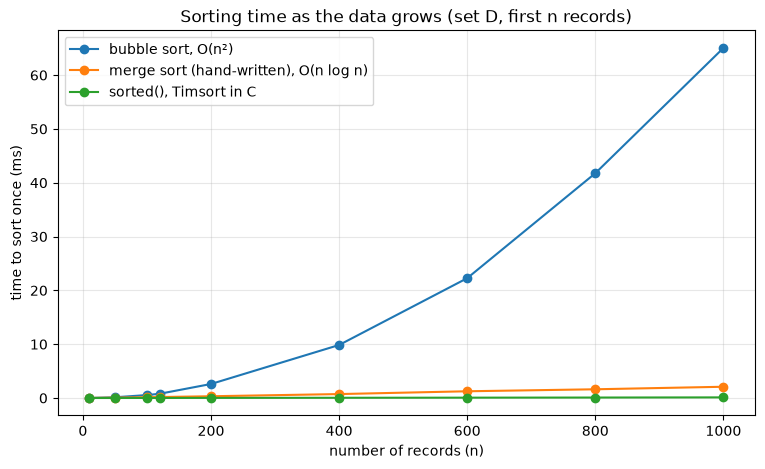

In [6]:
import matplotlib.pyplot as plt

big = datasets.make_dataset("D")
sizes = [10, 50, 100, 120, 200, 400, 600, 800, 1000]
times = {"bubble": [], "merge": [], "builtin": []}

for n in sizes:
    result = sort_group.benchmark_sort(big[:n], key=by_available)
    for method in times:
        times[method].append(result[method])

print(f"{'n':>6} {'bubble (ms)':>13} {'merge (ms)':>12} {'sorted() (ms)':>15}")
for i, n in enumerate(sizes):
    print(f"{n:>6,} {times['bubble'][i]:>13.3f} {times['merge'][i]:>12.3f} {times['builtin'][i]:>15.3f}")

plt.figure(figsize=(9, 5))
plt.plot(sizes, times["bubble"], marker="o", label="bubble sort, O(n²)")
plt.plot(sizes, times["merge"], marker="o", label="merge sort (hand-written), O(n log n)")
plt.plot(sizes, times["builtin"], marker="o", label="sorted(), Timsort in C")
plt.xlabel("number of records (n)")
plt.ylabel("time to sort once (ms)")
plt.title("Sorting time as the data grows (set D, first n records)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### อ่านกราฟนี้ยังไง

- เส้นของ bubble sort โค้งชันขึ้นเรื่อยๆ — ข้อมูลเพิ่มเป็นสองเท่า เวลาเพิ่มประมาณสี่เท่า ตามรูปแบบ n²
- เส้นของ merge sort แทบเป็นเส้นตรงเตี้ยๆ เพราะ n log n โตช้ากว่า n² มาก
- ที่ n น้อยๆ (10–50) สามเส้นแทบซ้อนกัน — Big-O บอกพฤติกรรมตอน n โต ไม่ได้บอกว่าใครชนะที่ n น้อย
- ที่ n = 120 ความต่างเริ่มเห็นแล้ว แต่ยังไม่ชัดเท่าที่ 1,000 รายการ นี่คือเหตุผลที่ทีมขยายชุด D เป็น 1,000

---
## 5. การจัดกลุ่ม

### 5.1 ผลการจัดกลุ่มชุด A–D

ทุกชุดต้องได้ผลรวมของทุกกลุ่มเท่ากับจำนวนรายการทั้งหมด — ไม่มีรายการหายหรือเกิน
ชื่อหมวดเป็นภาษาไทยตามข้อมูลจริงใน `datasets.py`

In [7]:
for name in "ABCD":
    items = datasets.make_dataset(name)
    by_type = sort_group.group_by_type(items)
    by_status = sort_group.group_by_status(items)
    assert sum(len(group) for group in by_type.values()) == len(items)
    assert sum(len(group) for group in by_status.values()) == len(items)
    print(f"ชุด {name} ({len(items):,} รายการ)")
    print("    ตามหมวด :", {category: len(group) for category, group in by_type.items()})
    print("    ตามสถานะ:", {status: len(group) for status, group in by_status.items()})

ชุด A (10 รายการ)
    ตามหมวด : {'เลนส์': 2, 'ขาตั้ง': 2, 'ไฟ': 2, 'ไมโครโฟน': 2, 'กล้อง': 2}
    ตามสถานะ: {'ok': 9, 'out': 0, 'broken': 1}
ชุด B (12 รายการ)
    ตามหมวด : {'เลนส์': 4, 'ไฟ': 2, 'กล้อง': 2, 'ขาตั้ง': 2, 'ไมโครโฟน': 2}
    ตามสถานะ: {'ok': 7, 'out': 4, 'broken': 1}
ชุด C (10 รายการ)
    ตามหมวด : {'เลนส์': 2, 'ขาตั้ง': 2, 'ไฟ': 2, 'ไมโครโฟน': 2, 'กล้อง': 2}
    ตามสถานะ: {'ok': 5, 'out': 4, 'broken': 1}
ชุด D (1,000 รายการ)
    ตามหมวด : {'เลนส์': 200, 'ขาตั้ง': 200, 'ไฟ': 200, 'ไมโครโฟน': 200, 'กล้อง': 200}
    ตามสถานะ: {'ok': 616, 'out': 242, 'broken': 142}


### 5.2 ทำไมแบ่งถังรอบเดียวเร็วกว่าวนหาทีละหมวด

**แบ่งถัง (`group_by_type`)** — เดินข้อมูล **รอบเดียว** แต่ละรายการเปิดถังของหมวดตัวเองใน `dict` (เฉลี่ย O(1)) แล้ว `append`
อ่านข้อมูล n ครั้ง ไม่ว่าจะมีกี่หมวด = **O(n)**

**วนหาทีละหมวด** — วนหาแต่ "กล้อง" ทั้งก้อนก่อน แล้ววนใหม่หา "เลนส์" ไปเรื่อยๆ
ต้องอ่านข้อมูลทั้งก้อนซ้ำเท่าจำนวนหมวด k = n × k ครั้ง = **O(n × k)**
ชุดข้อมูลของทีมมี 5 หมวด วิธีนี้จึงอ่านข้อมูลมากกว่า 5 เท่า และยิ่งร้านมีหมวดมาก ยิ่งห่าง

เซลล์ข้างล่างเขียนวิธีวนหาทีละหมวดไว้เทียบ (อยู่ใน notebook นี้เท่านั้น ไม่ได้อยู่ใน `sort_group.py`)
เขียนด้วยลูปธรรมดาแบบเดียวกับ `group_by_type` จะได้เทียบกันแฟร์ๆ
แล้วนับจำนวนครั้งที่อ่านข้อมูล · ตรวจว่าได้กลุ่มเหมือนกันทุกรายการ · และวัดเวลาบนชุด D

In [8]:
def group_one_category_at_a_time(items, categories):
    """วิธีเทียบ: วนอ่านข้อมูลทั้งก้อนใหม่ทุกหมวด — O(n × k)"""
    groups = {}
    for category in categories:
        group = []
        for item in items:
            if item["category"] == category:
                group.append(item)
        if group:
            groups[category] = group
    return groups


items = datasets.make_dataset("D")
categories = datasets.CATEGORIES

# ต้องได้กลุ่มเดียวกันทุกหมวด ทุกรายการ และลำดับในกลุ่มเหมือนเดิม
bucket_codes = {name: [item["code"] for item in group] for name, group in sort_group.group_by_type(items).items()}
naive_codes = {name: [item["code"] for item in group] for name, group in group_one_category_at_a_time(items, categories).items()}
assert bucket_codes == naive_codes

bucket_ms = sort_group.measure(lambda: sort_group.group_by_type(items))
naive_ms = sort_group.measure(lambda: group_one_category_at_a_time(items, categories))

print(f"ชุด D: {len(items):,} รายการ · {len(categories)} หมวด · ได้กลุ่มเหมือนกันทุกรายการ (ตรวจด้วย assert แล้ว)")
print()
print(f"แบ่งถังรอบเดียว   อ่านข้อมูล {len(items):>6,} ครั้ง   ใช้เวลา {bucket_ms:.3f} ms")
print(f"วนหาทีละหมวด     อ่านข้อมูล {len(items) * len(categories):>6,} ครั้ง   ใช้เวลา {naive_ms:.3f} ms")
print()
print(f"วนหาทีละหมวดอ่านข้อมูลมากกว่า {len(categories)} เท่า และใช้เวลานานกว่า {naive_ms / bucket_ms:.1f} เท่า")

ชุด D: 1,000 รายการ · 5 หมวด · ได้กลุ่มเหมือนกันทุกรายการ (ตรวจด้วย assert แล้ว)

แบ่งถังรอบเดียว   อ่านข้อมูล  1,000 ครั้ง   ใช้เวลา 0.069 ms
วนหาทีละหมวด     อ่านข้อมูล  5,000 ครั้ง   ใช้เวลา 0.141 ms

วนหาทีละหมวดอ่านข้อมูลมากกว่า 5 เท่า และใช้เวลานานกว่า 2.1 เท่า


### 5.3 เพิ่มจำนวนหมวด — พิสูจน์ว่า O(n) กับ O(n × k) โตต่างกัน

ใช้ชุด D 1,000 รายการเท่าเดิม แต่ตั้งหมวดใหม่ให้มี k = 5 · 10 · 20 · 50 หมวด (ก็อปแต่ละรายการแล้วเปลี่ยนแค่หมวด ข้อมูลจริงไม่ถูกแก้)
ถ้าทฤษฎีถูก เวลาของวนหาทีละหมวดต้องโตตาม k ส่วนแบ่งถังต้องแทบไม่เปลี่ยน

   k   bucket (ms)   one by one (ms)    ratio
   5         0.082             0.172     2.1x
  10         0.080             0.328     4.1x
  20         0.095             0.579     6.1x
  50         0.079             1.399    17.7x


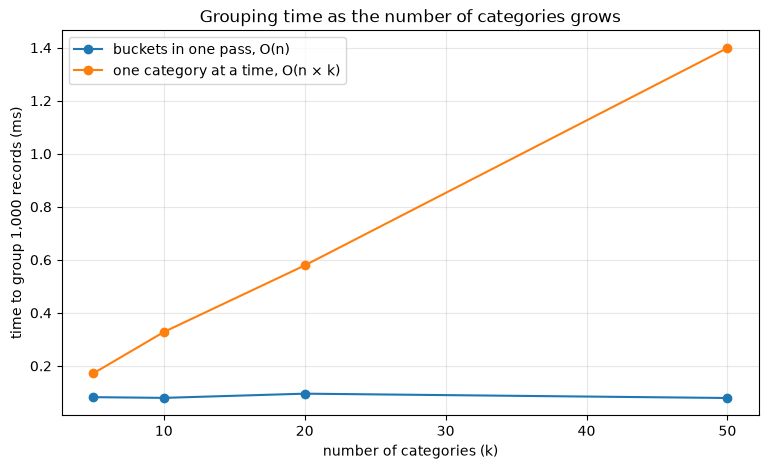

In [9]:
ks = [5, 10, 20, 50]
bucket_times, naive_times = [], []

print(f"{'k':>4} {'bucket (ms)':>13} {'one by one (ms)':>17} {'ratio':>8}")
for k in ks:
    relabelled = [dict(item, category=f"cat-{index % k}") for index, item in enumerate(items)]
    names = [f"cat-{number}" for number in range(k)]
    bucket_times.append(sort_group.measure(lambda: sort_group.group_by_type(relabelled)))
    naive_times.append(sort_group.measure(lambda: group_one_category_at_a_time(relabelled, names)))
    print(f"{k:>4} {bucket_times[-1]:>13.3f} {naive_times[-1]:>17.3f} {naive_times[-1] / bucket_times[-1]:>7.1f}x")

plt.figure(figsize=(9, 5))
plt.plot(ks, bucket_times, marker="o", label="buckets in one pass, O(n)")
plt.plot(ks, naive_times, marker="o", label="one category at a time, O(n × k)")
plt.xlabel("number of categories (k)")
plt.ylabel("time to group 1,000 records (ms)")
plt.title("Grouping time as the number of categories grows")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### อ่านผลข้อ 5 ยังไง

- **จำนวนครั้งที่อ่านข้อมูล** คือสิ่งที่ Big-O นับ: แบ่งถังอ่าน n ครั้ง วนหาทีละหมวดอ่าน n × k ครั้ง
- **เวลาจริงอาจห่างกันน้อยกว่า k เท่า** เพราะงานต่อหนึ่งรอบไม่เท่ากัน แบ่งถังต้องเปิดถังใน `dict` ทุกรอบ
  ส่วนวนหาทีละหมวดแค่เทียบชื่อหมวด — Big-O บอกอัตราการโต ไม่ได้บอกค่าคงที่
- **ข้อ 5.3 คือหลักฐานของอัตราการโต** เพิ่มจำนวนหมวด เส้นของวนหาทีละหมวดชันขึ้นตาม k ส่วนแบ่งถังแทบเป็นเส้นนอน
- ทั้งสองวิธีใช้หน่วยความจำ O(n) เท่ากัน เพราะทุกรายการถูกเก็บลงกลุ่มใดกลุ่มหนึ่ง (เก็บตัวอ้างอิง ไม่ได้ก็อปรายการ)

---
## 6. สรุป

1. **ชุดเล็ก (10 รายการ) ต่างกันนิดเดียว** — bubble sort ทันหรือเร็วกว่า merge sort ด้วยซ้ำ
   Big-O บอกพฤติกรรมตอน n โต ไม่ได้บอกว่าใครชนะที่ n น้อยๆ
2. **ชุด D (1,000 รายการ) bubble sort แพ้ขาด** — O(n²) โตเร็วกว่า O(n log n) มาก เห็นได้ทั้งในตาราง (ข้อ 3) และกราฟ (ข้อ 4)
3. **`sorted()` เร็วกว่า merge sort ของเรา** แต่เป็น O(n log n) เหมือนกัน — ต่างกันที่ค่าคงที่ เพราะ Timsort เขียนด้วยภาษา C
4. **merge sort เป็น stable** เพราะ `_merge` เทียบด้วย `<=` ค่าเท่ากันหยิบฝั่งซ้ายก่อน ลำดับเดิมจึงไม่ถูกสลับ
5. **จัดกลุ่มด้วยการแบ่งถังรอบเดียว = O(n)** ส่วนวนหาทีละหมวด = O(n × k) — ยิ่งหมวดมาก ยิ่งห่าง (ข้อ 5.3)

Flowchart ของส่วนนี้อยู่ในโฟลเดอร์ `flowcharts/` — `flow_kul_6_merge_sort` (merge sort) และ `flow_kul_7_group` (การจัดกลุ่ม)